The aim of this project is to predict whether an online shopper will make a purchase based on their e-commerce shopping behavior. The target variable is Revenue, which represents whether the customer completed a purchase during their shopping session

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    BaggingClassifier
)
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

### Dataset Loading

In [4]:
df=pd.read_csv("online_shoppers_intention.csv");
df.head()


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [5]:
print("Shape:", df.shape)

print("Columns:", df.columns)

print("Data Types:", df.dtypes)

print("Missing Values:", df.isnull().sum())

print("Duplicate Rows:", df.duplicated().sum())

print("Statistical summary:" ,df.describe())
df.info()

Shape: (12330, 18)
Columns: Index(['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month',
       'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType',
       'Weekend', 'Revenue'],
      dtype='object')
Data Types: Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
Revenue         

In [6]:
X = df.drop("Revenue", axis=1)
y = df["Revenue"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (12330, 17)
y shape: (12330,)


<h4>Distrubution of Numerical Features</h4>

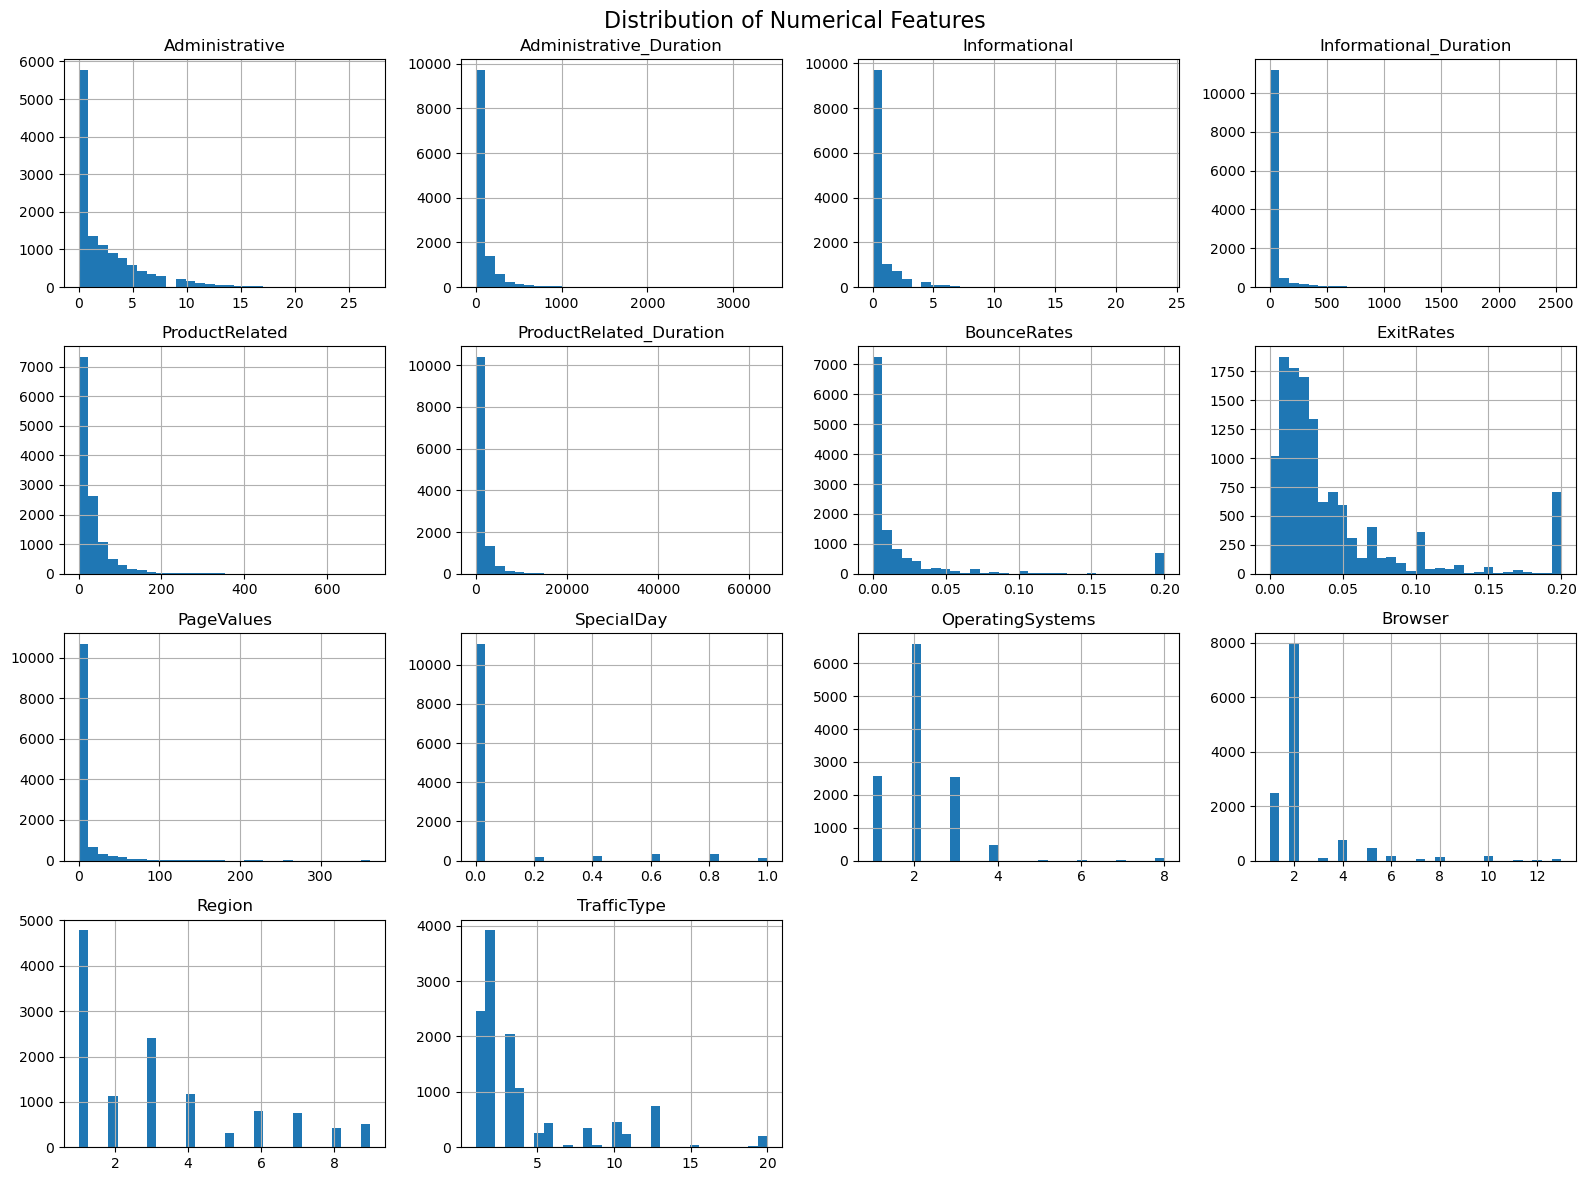

In [7]:
numeric_columns = df.select_dtypes(include=np.number).columns

df[numeric_columns].hist(
    figsize=(16, 12),
    bins=30
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

Most values are low, while a few sessions have very high values.
This shows that the data is right-skewed, and the features have different scales.

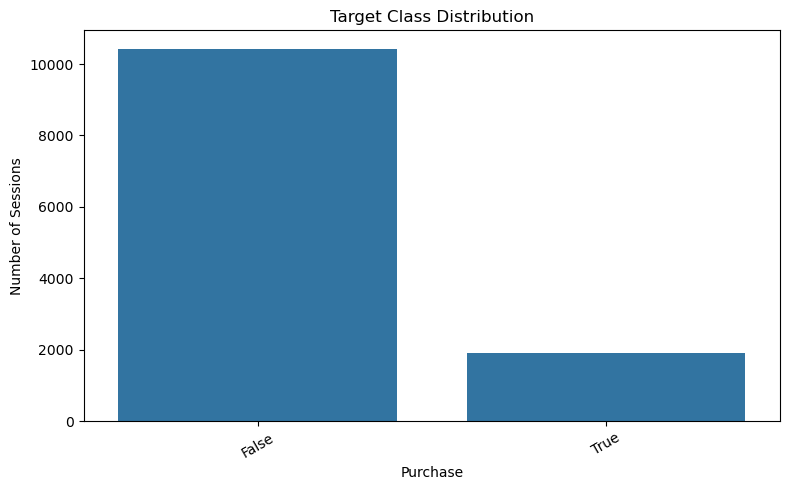

In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Revenue"
)

plt.xlabel("Purchase")
plt.ylabel("Number of Sessions")
plt.title("Target Class Distribution")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

Most sessions do not result in a purchase, while only a smaller proportion lead to a purchase, indicating an imbalance between the target classes.

<h4>Correlation Heatmap</h4>

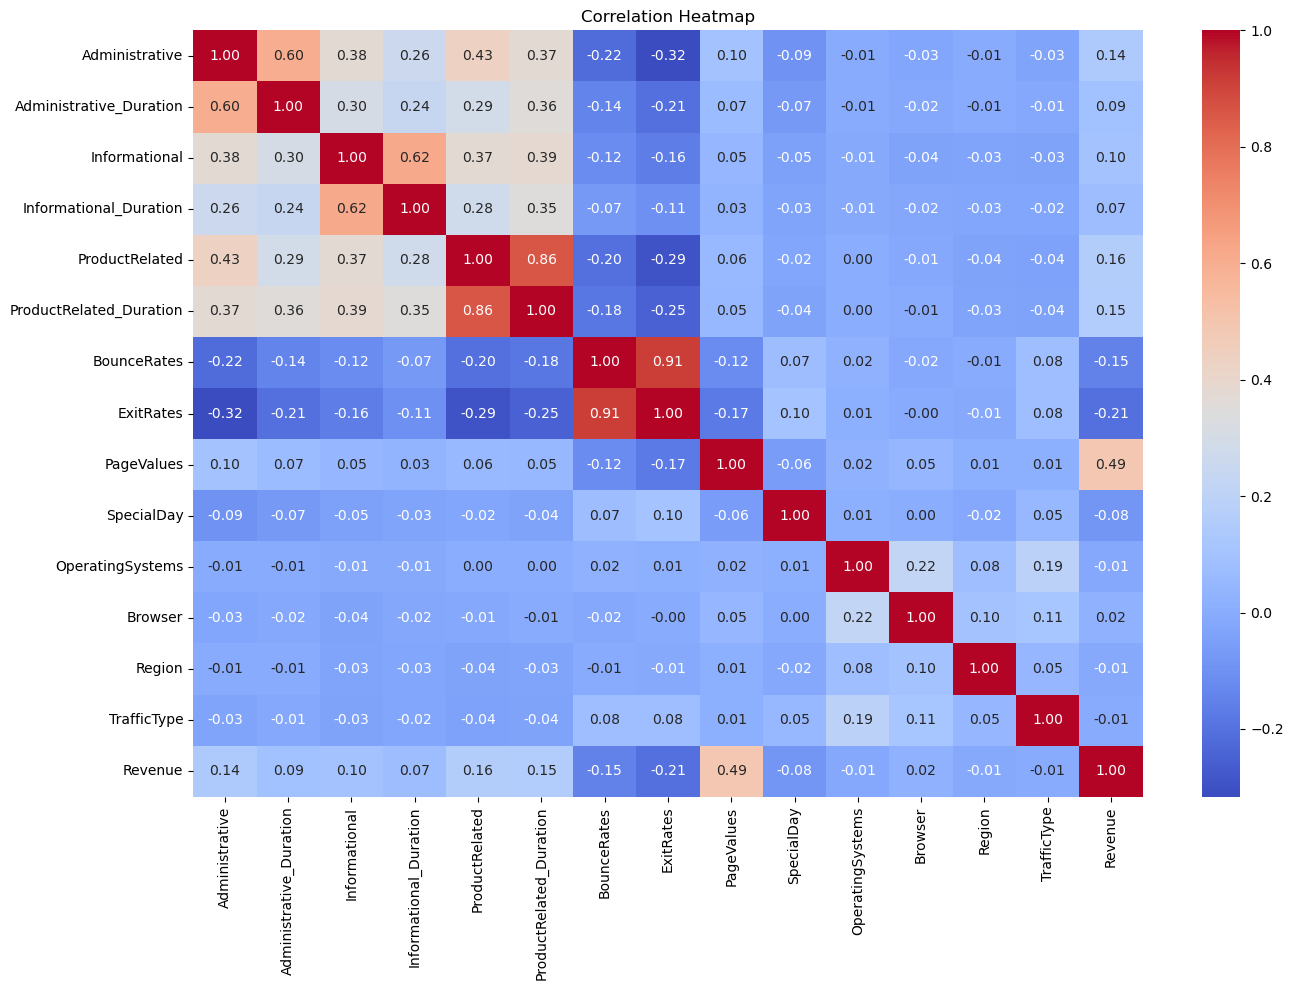

In [9]:
correlation = df.copy()
correlation["Revenue"] = correlation["Revenue"].astype(int)

plt.figure(figsize=(14, 10))
sns.heatmap(
    correlation.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


The heatmap shows how the numerical features are related to each other and to Revenue. Some browsing features have stronger relationships, while others have weak relationships.

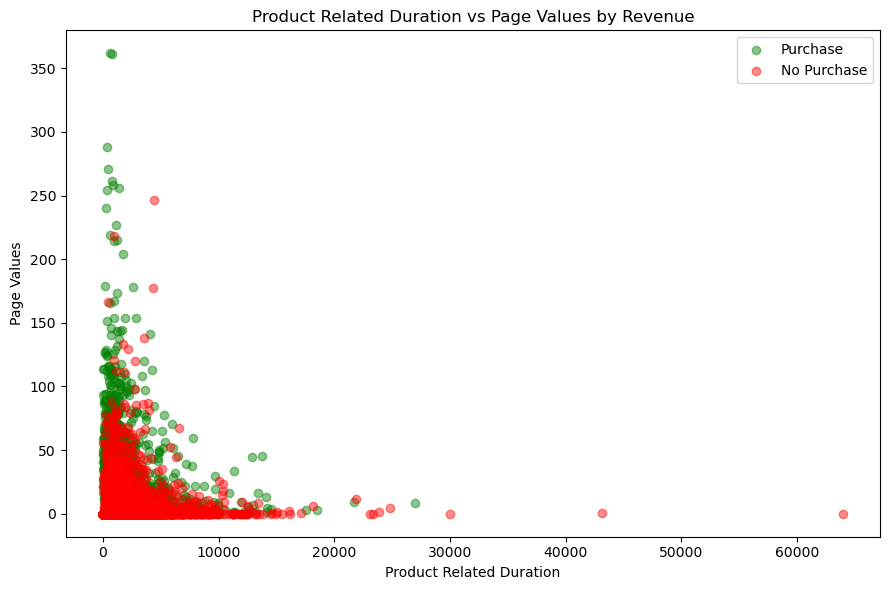

In [10]:
plt.figure(figsize=(9, 6))

for value, color, label in [(True, "green", "Purchase"), (False, "red", "No Purchase")]:
    data = df[df["Revenue"] == value]
    plt.scatter(
        data["ProductRelated_Duration"],
        data["PageValues"],
        color=color,
        alpha=0.45,
        label=label
    )

plt.xlabel("Product Related Duration")
plt.ylabel("Page Values")
plt.title("Product Related Duration vs Page Values by Revenue")
plt.legend()
plt.tight_layout()
plt.show()

High Page Values occur at low to moderate durations. Sessions with high Page Values are mostly purchases, so Page Values separates the two classes better than duration does.

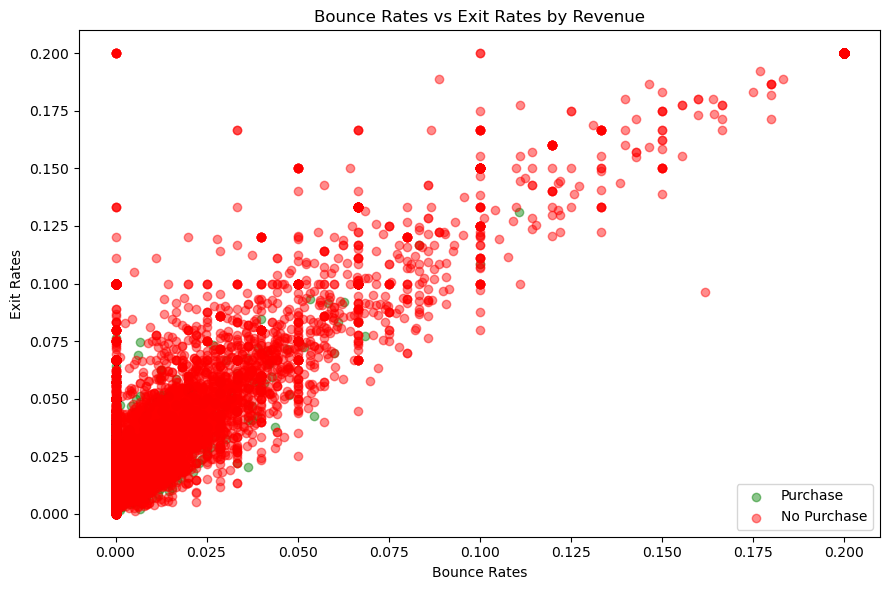

In [11]:
plt.figure(figsize=(9, 6))

for value, color, label in [
    (True, "green", "Purchase"),
    (False, "red", "No Purchase")
]:
    data = df[df["Revenue"] == value]

    plt.scatter(
        data["BounceRates"],
        data["ExitRates"],
        color=color,
        alpha=0.45,
        label=label
    )

plt.xlabel("Bounce Rates")
plt.ylabel("Exit Rates")
plt.title("Bounce Rates vs Exit Rates by Revenue")
plt.legend()

plt.tight_layout()
plt.show()

The plot shows that Bounce Rates and Exit Rates increase together. Both Purchase and No Purchase sessions appear in the same areas, so the two groups do not have a clear separation.

## Data Preprocessing and Feature Engineering

<h4>Missing Value Handling</h4>

In [12]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64


In [13]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 125


In [14]:
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (12205, 18)


In [15]:
X = df.drop("Revenue", axis=1)
y = df["Revenue"]

print("Features:")
print(X.columns)

print("\nTarget:")
print(y.name)

Features:
Index(['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month',
       'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType',
       'Weekend'],
      dtype='object')

Target:
Revenue


In [18]:
numeric_columns = df.select_dtypes(include=np.number).columns
categorical_columns = df.select_dtypes(
    include=["object", "bool"]).columns

for column in numeric_columns:
    if df[column].isnull().any():
        df[column] = df[column].fillna(df[column].median())

for column in categorical_columns:
    if df[column].isnull().any():
        df[column] = df[column].fillna(df[column].mode()[0])

print("Missing Values After Cleaning:")
print(df.isnull().sum())

Missing Values After Cleaning:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64


<h4>Handling Outliers </h4>

In [19]:
numeric_features = df.select_dtypes(include=np.number).columns

for column in numeric_features:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[column] = df[column].clip(lower, upper)
print(X.shape)

(12205, 17)


<h4>Feature Engineering</h4>

In [20]:
df["Total_Duration"] = (
    df["Administrative_Duration"]
    + df["Informational_Duration"]
    + df["ProductRelated_Duration"]
)

df["Total_Pages"] = (
    df["Administrative"]
    + df["Informational"]
    + df["ProductRelated"]
)

print(df[["Total_Duration", "Total_Pages"]].head())
df.head()

   Total_Duration  Total_Pages
0        0.000000            1
1       64.000000            2
2        0.000000            1
3        2.666667            2
4      627.500000           10


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,Total_Duration,Total_Pages
0,0,0.0,0,0.0,1,0.000000,0.041667,0.099977,0.0,0.0,Feb,1.0,2,1.0,1,Returning_Visitor,False,False,0.000000,1
1,0,0.0,0,0.0,2,64.000000,0.000000,0.099977,0.0,0.0,Feb,2.0,2,1.0,2,Returning_Visitor,False,False,64.000000,2
2,0,0.0,0,0.0,1,0.000000,0.041667,0.099977,0.0,0.0,Feb,4.0,2,8.5,3,Returning_Visitor,False,False,0.000000,1
3,0,0.0,0,0.0,2,2.666667,0.041667,0.099977,0.0,0.0,Feb,3.0,2,2.0,4,Returning_Visitor,False,False,2.666667,2
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.0,0.0,Feb,3.0,2,1.0,4,Returning_Visitor,True,False,627.500000,10


In [22]:
X = df.drop("Revenue", axis=1)
y = df["Revenue"]

categorical_features = list(
    X.select_dtypes(include=["object",  "bool"]).columns
) + ["OperatingSystems", "Browser", "Region", "TrafficType"]

X = pd.get_dummies(
    X,
    columns=categorical_features,
    drop_first=True
)

print("Shape after encoding:", X.shape)
X.head()

Shape after encoding: (12205, 42)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Region_6.0,Region_7.0,Region_8.0,Region_8.5,TrafficType_2,TrafficType_3,TrafficType_4,TrafficType_5,TrafficType_6,TrafficType_7
0,0,0.0,0,0.0,1,0.000000,0.041667,0.099977,0.0,0.0,...,False,False,False,False,False,False,False,False,False,False
1,0,0.0,0,0.0,2,64.000000,0.000000,0.099977,0.0,0.0,...,False,False,False,False,True,False,False,False,False,False
2,0,0.0,0,0.0,1,0.000000,0.041667,0.099977,0.0,0.0,...,False,False,False,True,False,True,False,False,False,False
3,0,0.0,0,0.0,2,2.666667,0.041667,0.099977,0.0,0.0,...,False,False,False,False,False,False,True,False,False,False
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.0,0.0,...,False,False,False,False,False,False,True,False,False,False


In [23]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,Total_Duration,Total_Pages
0,0,0.0,0,0.0,1,0.000000,0.041667,0.099977,0.0,0.0,Feb,1.0,2,1.0,1,Returning_Visitor,False,False,0.000000,1
1,0,0.0,0,0.0,2,64.000000,0.000000,0.099977,0.0,0.0,Feb,2.0,2,1.0,2,Returning_Visitor,False,False,64.000000,2
2,0,0.0,0,0.0,1,0.000000,0.041667,0.099977,0.0,0.0,Feb,4.0,2,8.5,3,Returning_Visitor,False,False,0.000000,1
3,0,0.0,0,0.0,2,2.666667,0.041667,0.099977,0.0,0.0,Feb,3.0,2,2.0,4,Returning_Visitor,False,False,2.666667,2
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.0,0.0,Feb,3.0,2,1.0,4,Returning_Visitor,True,False,627.500000,10


In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (9764, 42)
Testing data: (2441, 42)


In [25]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

StandardScaler was used to bring the numerical features to a similar scale. This is important because some features have larger values than others, which can affect distance-based and scale-sensitive models. The scaler was fitted only on the training data and then used to transform the test data to avoid data leakage.

<h2>Classification Algorithm Implementation</h2>

In [26]:
# Part A
models_A = {
    "Logistic Regression": LogisticRegression(
        max_iter=5000, class_weight="balanced", random_state=42
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=7),
    "Gaussian Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8, class_weight="balanced", random_state=42
    ),
    "Support Vector Machine": SVC(
        kernel="rbf", class_weight="balanced", probability=True, random_state=42
    )
}

# Part B
models_B = {
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1),
        {"n_estimators": [100, 200], "max_depth": [None, 12]}
    ),
    "AdaBoost": (
        AdaBoostClassifier(random_state=42),
        {"n_estimators": [50, 100], "learning_rate": [0.5, 1.0]}
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=42),
        {"n_estimators": [100, 150], "learning_rate": [0.05, 0.1], "max_depth": [2, 3]}
    ),
    "Bagging (Decision Tree)": (
        BaggingClassifier(
            estimator=DecisionTreeClassifier(random_state=42),
            random_state=42, n_jobs=-1
        ),
        {"n_estimators": [50, 100], "max_samples": [0.8, 1.0]}
    ),
    "MLP Neural Network": (
        MLPClassifier(max_iter=300, early_stopping=True, random_state=42),
        {"hidden_layer_sizes": [(50,), (100,)], "activation": ["relu", "tanh"]}
    )
}

print("Part A algorithms:", len(models_A))
print("Part B algorithms to tune:", len(models_B))

Part A algorithms: 5
Part B algorithms to tune: 5


In [27]:
results = []
predictions = {}
fitted_models = {}
best_parameters = {}

# Train the first five models
for name, model in models_A.items():
    model.fit(X_train_scaled, y_train)
    fitted_models[name] = model

# Tune and train the five Part-B models
for name, (model, param_grid) in models_B.items():
    search = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        scoring="f1_weighted",
        cv=3,
        n_jobs=-1,
        verbose=0
    )
    search.fit(X_train_scaled, y_train)
    fitted_models[name] = search.best_estimator_
    best_parameters[name] = search.best_params_
    print(name, "best parameters:", search.best_params_)

# Evaluate all ten models on the same held-out test set
for name, model in fitted_models.items():
    pred = model.predict(X_test_scaled)
    predictions[name] = pred

    if hasattr(model, "predict_proba"):
        score = model.predict_proba(X_test_scaled)[:, 1]
    elif hasattr(model, "decision_function"):
        score = model.decision_function(X_test_scaled)
    else:
        score = pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (weighted)": precision_score(y_test, pred, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(y_test, pred, average="weighted", zero_division=0),
        "F1-score (weighted)": f1_score(y_test, pred, average="weighted", zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, score, multi_class="ovr") if y_test.nunique() == 2
                   else roc_auc_score(y_test, model.predict_proba(X_test_scaled), multi_class="ovr", average="weighted")
    })

comparison = pd.DataFrame(results).sort_values(
    "F1-score (weighted)", ascending=False
).reset_index(drop=True)

display(comparison.round(4))

Random Forest best parameters: {'max_depth': 12, 'n_estimators': 200}
AdaBoost best parameters: {'learning_rate': 1.0, 'n_estimators': 100}
Gradient Boosting best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 150}
Bagging (Decision Tree) best parameters: {'max_samples': 0.8, 'n_estimators': 100}
MLP Neural Network best parameters: {'activation': 'tanh', 'hidden_layer_sizes': (100,)}


,Model,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),ROC-AUC
0,Bagging (Decision Tree),0.8415,0.7985,0.8415,0.8018,0.7426
1,Gradient Boosting,0.8394,0.7875,0.8394,0.7919,0.7846
2,Random Forest,0.7714,0.8151,0.7714,0.7888,0.7793
3,MLP Neural Network,0.8386,0.7828,0.8386,0.7886,0.7551
4,K-Nearest Neighbors,0.8222,0.7630,0.8222,0.7821,0.6382
5,AdaBoost,0.8435,0.7924,0.8435,0.7801,0.7561
6,Gaussian Naive Bayes,0.6796,0.8063,0.6796,0.7205,0.7227
7,Support Vector Machine,0.6731,0.8246,0.6731,0.7168,0.7506
8,Logistic Regression,0.6448,0.8315,0.6448,0.6933,0.7560
9,Decision Tree,0.6022,0.8220,0.6022,0.6561,0.7188
